In [1]:
import ctypes, glob, sys
for lib in glob.glob(f"{sys.prefix}/lib/python3*/site-packages/nvidia/cusolver/lib/libcusolver.so.*"):
    ctypes.CDLL(lib, mode=ctypes.RTLD_GLOBAL)

import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1794155433.569350   25228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794155433.628540   25228 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794155434.914317   25228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import pickle
import numpy as np

C10_DIR = "docs/cifar-10-batches-py"
C100_DIR = "docs/cifar-100-python"

def unpickle(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="bytes")

def to_images(flat):
    return np.asarray(flat).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

# CIFAR-10
c10_names = [n.decode() for n in unpickle(f"{C10_DIR}/batches.meta")[b"label_names"]]
batches = [unpickle(f"{C10_DIR}/data_batch_{i}") for i in range(1, 6)]
x10_train = to_images(np.concatenate([b[b"data"] for b in batches]))
y10_train = np.concatenate([b[b"labels"] for b in batches])
test10 = unpickle(f"{C10_DIR}/test_batch")
x10_test = to_images(test10[b"data"])
y10_test = np.asarray(test10[b"labels"])

# CIFAR-100
meta100 = unpickle(f"{C100_DIR}/meta")
fine_names = [n.decode() for n in meta100[b"fine_label_names"]]
coarse_names = [n.decode() for n in meta100[b"coarse_label_names"]]
train100 = unpickle(f"{C100_DIR}/train")
test100 = unpickle(f"{C100_DIR}/test")
x100_train = to_images(train100[b"data"])
y100_fine_train = np.array(train100[b"fine_labels"])
y100_coarse_train = np.array(train100[b"coarse_labels"])
x100_test = to_images(test100[b"data"])
y100_fine_test = np.array(test100[b"fine_labels"])
y100_coarse_test = np.array(test100[b"coarse_labels"])

print(x10_train.shape)
print(x10_test.shape)
print(x100_train.shape)
print(x100_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 32, 32, 3)
(10000, 32, 32, 3)


# Visual test of CIFAR 10 / 100 images

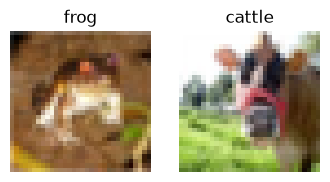

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(4, 2))
axes[0].imshow(x10_train[0]); axes[0].set_title(c10_names[y10_train[0]])
axes[1].imshow(x100_train[0]); axes[1].set_title(fine_names[y100_fine_train[0]])
for ax in axes:
    ax.axis("off")
plt.show()

# Phase 2: Filter and combine the 24 classes

Keep 7 classes from CIFAR-10, 16 fine classes and the `trees` superclass from CIFAR-100, then relabel them to a single 0-23 range.

In [ ]:
num_classes = 24
c10_classes = ["automobile", "bird", "cat", "deer", "dog", "horse", "truck"]
c100_classes = [
    "cattle", "fox", "baby", "boy", "girl", "man", "woman", "rabbit", "squirrel",
    "bicycle", "bus", "motorcycle", "pickup_truck", "train", "lawn_mower", "tractor",
]
class_names = c10_classes + c100_classes + ["trees"]


def extract_classes(X, y, source_names, wanted_classes):
    X_selected = []
    y_selected = []
    for name in wanted_classes:
        X_class = X[y == source_names.index(name)]
        X_selected.append(X_class)
        y_selected.append(np.full(len(X_class), class_names.index(name)))
    return np.concatenate(X_selected), np.concatenate(y_selected)


def combine_datasets(X10, y10, X100, y100_fine, y100_coarse):
    X_a, y_a = extract_classes(X10, y10, c10_names, c10_classes)
    X_b, y_b = extract_classes(X100, y100_fine, fine_names, c100_classes)
    X_c, y_c = extract_classes(X100, y100_coarse, coarse_names, ["trees"])
    return np.concatenate((X_a, X_b, X_c)), np.concatenate((y_a, y_b, y_c))


def check_data(X_train, y_train, X_test, y_test):
    print(X_train.shape)
    print(X_test.shape)
    assert(len(class_names) == num_classes), "The number of class names is not 24"
    assert(X_train.shape[0] == y_train.shape[0]), "The number of training images does not match the number of labels"
    assert(X_test.shape[0] == y_test.shape[0]), "The number of test images does not match the number of labels"
    assert(X_train.shape[1:] == (32, 32, 3)), "The dimensions of the training images are not 32 x 32 x 3"
    assert(X_test.shape[1:] == (32, 32, 3)), "The dimensions of the test images are not 32 x 32 x 3"
    assert(X_train.shape[0] == 45500), "The training set should have 45500 images"
    assert(X_test.shape[0] == 9100), "The test set should have 9100 images"


X_train, y_train = combine_datasets(x10_train, y10_train, x100_train, y100_fine_train, y100_coarse_train)
X_test, y_test = combine_datasets(x10_test, y10_test, x100_test, y100_fine_test, y100_coarse_test)
check_data(X_train, y_train, X_test, y_test)

for class_id, name in enumerate(class_names):
    print(class_id, name)

(45500, 32, 32, 3)
(9100, 32, 32, 3)
0 automobile
1 bird
2 cat
3 deer
4 dog
5 horse
6 truck
7 cattle
8 fox
9 baby
10 boy
11 girl
12 man
13 woman
14 rabbit
15 squirrel
16 bicycle
17 bus
18 motorcycle
19 pickup_truck
20 train
21 lawn_mower
22 tractor
23 trees
